# FIT · Step 1 & 2: Pull and clean one season

**FIT** is a basketball impact metric I'm building. It measures how much a player adds and how well players fit together.

This notebook is the data pipeline:

1. **Pull** every game of a season from NBA.com: the schedule, the play-by-play, and the rotations (who checked in and out, and when).
2. **Clean** it into **stints**: stretches of a game where the same 10 players are on the floor. For each stint we keep who was out there, how many points each team scored, and how many possessions it lasted.
3. **Check** every game against the official box score. Points have to add up to the final score, every stint needs exactly 5 players per team, and the stints have to cover the whole game. Games that fail get flagged and left out.

Output: `data/stints.csv`, the input for RAPM and later for FIT.

In [ ]:
%pip install nba_api
%pip install pandas, numpy

In [20]:
%pip install nba_api
%pip install pandas
%pip install matplotlib
%pip install seaborn
import os
import re
import time
import unicodedata

import pandas as pd
import numpy as np
from nba_api.stats import endpoints

from matplotlib import pyplot as plt
import seaborn as sns; sns.set_style('whitegrid')

pd.set_option('display.max_columns', 100)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
SEASON = '2025-26'

N_GAMES = None          # start small to make sure everything works, then set to None for the full season
SLEEP = 1.0           # pause between requests so NBA.com doesn't block us

DATA_DIR = 'data'
RAW_PBP_DIR = os.path.join(DATA_DIR, 'raw', 'pbp')
RAW_ROT_DIR = os.path.join(DATA_DIR, 'raw', 'rotation')

os.makedirs(RAW_PBP_DIR, exist_ok = True)
os.makedirs(RAW_ROT_DIR, exist_ok = True)

## Step 1: Pull the data

First the schedule. `LeagueGameFinder` gives one row per team per game, so every game shows up twice. `vs.` in the matchup means home, `@` means away.

In [22]:
games = endpoints.leaguegamefinder.LeagueGameFinder(season_nullable = SEASON,
                                                     league_id_nullable = '00',
                                                     season_type_nullable = 'Regular Season').league_game_finder_results.get_data_frame()

games['IS_HOME'] = games['MATCHUP'].str.contains('vs.', regex = False)

home = games.loc[games['IS_HOME'], ['GAME_ID', 'GAME_DATE', 'TEAM_ID', 'TEAM_ABBREVIATION', 'PTS']]
away = games.loc[~games['IS_HOME'], ['GAME_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'PTS']]

home.columns = ['GAME_ID', 'GAME_DATE', 'HOME_ID', 'HOME', 'HOME_PTS']
away.columns = ['GAME_ID', 'AWAY_ID', 'AWAY', 'AWAY_PTS']

game_list = home.merge(away, on = 'GAME_ID', how = 'inner').sort_values(['GAME_DATE', 'GAME_ID']).reset_index(drop = True)

game_list.to_csv(os.path.join(DATA_DIR, 'games.csv'), index = False)

print(f'Games found: {len(game_list)}')
game_list.head()

Games found: 1225


,GAME_ID,GAME_DATE,HOME_ID,HOME,HOME_PTS,AWAY_ID,AWAY,AWAY_PTS
0,0022500001,2025-10-21,1610612760,OKC,125,1610612745,HOU,124
1,0022500002,2025-10-21,1610612747,LAL,109,1610612744,GSW,119
2,0022500003,2025-10-22,1610612752,NYK,119,1610612739,CLE,111
3,0022500004,2025-10-22,1610612742,DAL,92,1610612759,SAS,125
4,0022500080,2025-10-22,1610612766,CHA,136,1610612751,BKN,117


Now the play-by-play and the rotation for every game. Each game is saved to its own file, so if the download stops (NBA.com times out sometimes) you can rerun the cell and it picks up where it left off.

In [23]:
def call_api(func, game_id, tries = 3):

    for attempt in range(tries):

        try:
            return func(game_id)

        except Exception as e:
            print(f'{game_id}: attempt {attempt + 1} failed ({e})')
            time.sleep(5 * (attempt + 1))

    return None


def get_pbp(game_id):
    return endpoints.playbyplayv3.PlayByPlayV3(game_id = game_id, timeout = 60).play_by_play.get_data_frame()


def get_rotation(game_id):

    rotation = endpoints.gamerotation.GameRotation(game_id = game_id, timeout = 60)

    home_rot = rotation.home_team.get_data_frame()
    away_rot = rotation.away_team.get_data_frame()

    home_rot['SIDE'] = 'HOME'
    away_rot['SIDE'] = 'AWAY'

    return pd.concat([home_rot, away_rot])


def get_box(game_id):
    return endpoints.boxscoretraditionalv3.BoxScoreTraditionalV3(game_id = game_id, timeout = 60).player_stats.get_data_frame()


def simple_name(name):
    return unicodedata.normalize('NFKD', str(name)).encode('ascii', 'ignore').decode().lower().strip()


def rotation_from_pbp(pbp, box, home_id, missing = None):

    pbp = pbp.sort_values('actionNumber').copy()

    clock = pbp['clock'].str.extract(r'PT(\d+)M([\d.]+)S').astype(float)
    period_start = np.where(pbp['period'] <= 4, (pbp['period'] - 1) * 7200, 28800 + (pbp['period'] - 5) * 3000)
    period_length = np.where(pbp['period'] <= 4, 7200, 3000)
    pbp['ELAPSED'] = period_start + period_length - (clock[0] * 60 + clock[1]) * 10
    pbp['ELAPSED'] = pbp['ELAPSED'].ffill().fillna(0)

    # some plays are logged late, so put them back in game order
    pbp = pbp.sort_values(['period', 'ELAPSED', 'actionNumber'], kind = 'stable')

    # the play-by-play only has the ID of the player going out, the one coming in is just a name
    team_of = dict(zip(box['personId'], box['teamId']))
    names = {}

    for _, p in box.iterrows():
        for name in [p['familyName'], p['nameI'], p['firstName'] + ' ' + p['familyName']]:
            names[(p['teamId'], simple_name(name))] = p['personId']

    for _, p in pbp.loc[pbp['personId'].isin(team_of)].iterrows():
        names.setdefault((p['teamId'], simple_name(p['playerName'])), p['personId'])

    # some players are called by their first name (Yang Hansen is 'Hansen')
    for _, p in box.iterrows():
        names.setdefault((p['teamId'], simple_name(p['firstName'])), p['personId'])

    is_sub = pbp['actionType'] == 'Substitution'
    sub_in = pbp['description'].str.extract(r'SUB: (.+) FOR ', expand = False)
    pbp['IN_ID'] = [names.get((t, simple_name(n))) if s else None for s, t, n in zip(is_sub, pbp['teamId'], sub_in)]

    # technical fouls can be called on players sitting on the bench
    pbp['ON_COURT_EVENT'] = ~is_sub & pbp['personId'].isin(team_of) & ~pbp['description'].str.contains(r'T\.FOUL|Technical', case = False, na = False)

    starters = box.loc[box['position'].fillna('') != '']
    on_floor = {team: list(group['personId']) for team, group in starters.groupby('teamId')}

    behind = [] if missing is None else missing.loc[missing > 0].sort_values(ascending = False).index

    rows = []

    for period, events in pbp.groupby('period'):

        start = (period - 1) * 7200 if period <= 4 else 28800 + (period - 5) * 3000
        end = start + (7200 if period <= 4 else 3000)

        if period > 1:

            # who started the period: anyone who shows up before being subbed in
            for team in on_floor:

                first, subbed_in = [], set()

                for _, e in events.loc[events['teamId'] == team].iterrows():

                    if e['actionType'] == 'Substitution':
                        if e['personId'] not in subbed_in and e['personId'] not in first:
                            first.append(e['personId'])
                        subbed_in.add(e['IN_ID'])

                    elif e['ON_COURT_EVENT'] and e['personId'] not in subbed_in and e['personId'] not in first:
                        first.append(e['personId'])

                # players who were on the floor the whole period without doing anything
                for p in on_floor[team]:
                    if len(first) < 5 and p not in first and p not in subbed_in:
                        first.append(p)

                # still short: whoever is furthest below their box score minutes
                for p in behind:
                    if len(first) < 5 and team_of[p] == team and p not in first and p not in subbed_in:
                        first.append(p)

                on_floor[team] = first[:5]

        in_time = {p: start for team in on_floor for p in on_floor[team]}

        for _, e in events.loc[is_sub].iterrows():

            team, out_id, in_id = e['teamId'], e['personId'], e['IN_ID']

            if out_id in on_floor.get(team, []):
                on_floor[team].remove(out_id)
                rows.append((team, out_id, in_time.pop(out_id), e['ELAPSED']))

            if pd.notna(in_id) and in_id not in on_floor.get(team, []):
                on_floor[team].append(in_id)
                in_time[in_id] = e['ELAPSED']

        for team in on_floor:
            for p in on_floor[team]:
                rows.append((team, p, in_time.pop(p), end))

    rot = pd.DataFrame(rows, columns = ['TEAM_ID', 'PERSON_ID', 'IN_TIME_REAL', 'OUT_TIME_REAL'])

    names = box[['personId', 'firstName', 'familyName']].rename(columns = {'personId': 'PERSON_ID', 'firstName': 'PLAYER_FIRST', 'familyName': 'PLAYER_LAST'})
    rot = rot.merge(names, on = 'PERSON_ID', how = 'left')

    rot.insert(0, 'GAME_ID', box['gameId'].iloc[0])
    rot['SIDE'] = np.where(rot['TEAM_ID'] == home_id, 'HOME', 'AWAY')

    rot = rot.loc[rot['OUT_TIME_REAL'] > rot['IN_TIME_REAL']]

    if missing is None:

        minutes = box['minutes'].fillna('').str.extract(r'(\d+):(\d+)').astype(float).fillna(0)
        official = pd.Series((minutes[0] * 60 + minutes[1]).values, index = box['personId'])
        rebuilt = ((rot['OUT_TIME_REAL'] - rot['IN_TIME_REAL']) / 10).groupby(rot['PERSON_ID']).sum()

        return rotation_from_pbp(pbp, box, home_id, missing = official.sub(rebuilt, fill_value = 0))

    return rot

In [24]:
%pip install -U nba_api

import requests
from importlib.metadata import version
from nba_api.stats.library.http import STATS_HEADERS

print('nba_api version:', version('nba_api'))
print('games already downloaded:', len(os.listdir(RAW_PBP_DIR)))

test_id = game_list['GAME_ID'].iloc[1]

tests = [('play-by-play', 'https://stats.nba.com/stats/playbyplayv3', {'GameID': test_id, 'StartPeriod': 0, 'EndPeriod': 0}),
         ('rotation', 'https://stats.nba.com/stats/gamerotation', {'GameID': test_id, 'LeagueID': '00'})]

for name, url, params in tests:

    r = requests.get(url, params = params, headers = STATS_HEADERS, timeout = 60)
    print(f'{name} | status: {r.status_code} | length: {len(r.text)} | {r.text[:120]}')

r = requests.get(f'https://cdn.nba.com/static/json/liveData/playbyplay/playbyplay_{test_id}.json', timeout = 60)
print(f'backup play-by-play | status: {r.status_code} | length: {len(r.text)}')

Note: you may need to restart the kernel to use updated packages.
nba_api version: 1.11.6
games already downloaded: 20



[notice] A new release of pip is available: 24.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


play-by-play | status: 200 | length: 220328 | {"meta":{"version":1,"request":"http://nba.cloud/games/0022500002/playbyplay?Format=json","time":"2025-11-05T14:42:20.42
rotation | status: 200 | length: 8033 | {"resource":"gamerotation","parameters":{"GameID":"0022500002","LeagueID":"00"},"resultSets":[{"name":"AwayTeam","header
backup play-by-play | status: 403 | length: 447


In [ ]:
game_ids = game_list['GAME_ID'].tolist()

if N_GAMES is not None:
    game_ids = game_ids[:N_GAMES]

failed = []
rebuilt = []
start_time = time.time()

for i, game_id in enumerate(game_ids):

    pbp_path = os.path.join(RAW_PBP_DIR, f'{game_id}.csv')
    rot_path = os.path.join(RAW_ROT_DIR, f'{game_id}.csv')

    if os.path.exists(pbp_path) and os.path.exists(rot_path):
        continue

    pbp = call_api(get_pbp, game_id)
    time.sleep(SLEEP)

    if pbp is None or len(pbp) == 0:
        failed.append(game_id)
        continue

    # NBA.com returns an error for the rotation of some games, so rebuild it from the play-by-play
    rot = call_api(get_rotation, game_id, tries = 2)
    time.sleep(SLEEP)

    if rot is None or len(rot) == 0:

        box = call_api(get_box, game_id)
        time.sleep(SLEEP)

        if box is None or len(box) == 0:
            failed.append(game_id)
            continue

        home_id = game_list.loc[game_list['GAME_ID'] == game_id, 'HOME_ID'].iloc[0]
        rot = rotation_from_pbp(pbp, box, home_id)
        rebuilt.append(game_id)

    pbp.to_csv(pbp_path, index = False)
    rot.to_csv(rot_path, index = False)

    if (i + 1) % 50 == 0:
        print(f'{i + 1} / {len(game_ids)} games downloaded ({(time.time() - start_time) / 60:.1f} min)')

print(f'Done. Rotations rebuilt from the play-by-play: {len(rebuilt)}. Games that failed to download: {len(failed)}')

0022500092: attempt 1 failed (Expecting value: line 1 column 1 (char 0))
0022500092: attempt 2 failed (Expecting value: line 1 column 1 (char 0))
0022500093: attempt 1 failed (Expecting value: line 1 column 1 (char 0))
0022500093: attempt 2 failed (Expecting value: line 1 column 1 (char 0))


## Step 2: Clean the data into stints

Time is measured in **tenths of a second since tip-off**, the same unit the rotation data uses. One quarter is 7,200 and a full game is 28,800. Overtime periods are 3,000 each.

The play-by-play clock counts down (`PT11M48.00S` means 11:48 left in the period), so it has to be converted into time since tip-off.

In [ ]:
def clock_to_elapsed(period, clock):

    found = re.findall(r'PT(\d+)M([\d.]+)S', clock) if isinstance(clock, str) else []

    if len(found) == 0:
        return np.nan

    minutes, seconds = found[0]
    remaining = (int(minutes) * 60 + float(seconds)) * 10

    if period <= 4:
        start, length = (period - 1) * 7200, 7200
    else:
        start, length = 28800 + (period - 5) * 3000, 3000

    return start + length - remaining


print(clock_to_elapsed(1, 'PT12M00.00S'))   # tip-off -> 0
print(clock_to_elapsed(2, 'PT06M00.00S'))   # halfway through the 2nd -> 10800
print(clock_to_elapsed(5, 'PT00M00.00S'))   # end of the first overtime -> 31800

0.0
10800.0
31800.0


For every play we need the points scored and the pieces of the possession estimate:

**Possessions = FGA + 0.44 × FTA − offensive rebounds + turnovers**

An offensive rebound is a rebound by the same team that just missed.

In [ ]:
def prep_pbp(pbp, home_id):

    pbp = pbp.sort_values('actionNumber').copy()

    pbp['ELAPSED'] = pbp.apply(lambda x: clock_to_elapsed(x.period, x.clock), axis = 1)
    pbp['ELAPSED'] = pbp['ELAPSED'].ffill().fillna(0)

    # the score is only filled in on scoring plays, so carry it forward
    pbp['scoreHome'] = pd.to_numeric(pbp['scoreHome'], errors = 'coerce').ffill().fillna(0)
    pbp['scoreAway'] = pd.to_numeric(pbp['scoreAway'], errors = 'coerce').ffill().fillna(0)

    pbp['PTS_HOME'] = pbp['scoreHome'].diff().fillna(pbp['scoreHome'])
    pbp['PTS_AWAY'] = pbp['scoreAway'].diff().fillna(pbp['scoreAway'])

    pbp['IS_HOME'] = pbp['teamId'] == home_id

    pbp['FGA'] = pbp['isFieldGoal'] == 1
    pbp['FTA'] = pbp['actionType'] == 'Free Throw'
    pbp['TOV'] = pbp['actionType'] == 'Turnover'

    pbp['MISS'] = (pbp['actionType'] == 'Missed Shot') | (pbp['FTA'] & pbp['description'].str.contains('MISS', na = False))

    last_miss_team = pbp['teamId'].where(pbp['MISS']).ffill()
    pbp['OREB'] = (pbp['actionType'] == 'Rebound') & (pbp['teamId'] == last_miss_team)

    return pbp


def count_possessions(rows):

    counts = rows.groupby('STINT')[['FGA', 'FTA', 'OREB', 'TOV']].sum()

    return counts['FGA'] + 0.44 * counts['FTA'] - counts['OREB'] + counts['TOV']

Building the stints:

- Every time someone checks in or out, a new stint starts.
- The players on the floor are the ones checked in at the middle of the stint.
- A play that happens at the exact moment of a substitution (like free throws right after a sub) is credited to the lineup that was on the floor **before** the sub.

In [ ]:
def build_stints(game_id, home_id, away_id):

    pbp = pd.read_csv(os.path.join(RAW_PBP_DIR, f'{game_id}.csv'))
    rot = pd.read_csv(os.path.join(RAW_ROT_DIR, f'{game_id}.csv'))

    pbp = prep_pbp(pbp, home_id)

    boundaries = np.unique(np.concatenate([rot['IN_TIME_REAL'], rot['OUT_TIME_REAL']]))

    stints = []

    for start, end in zip(boundaries[:-1], boundaries[1:]):

        mid = (start + end) / 2

        on_floor = rot.loc[(rot['IN_TIME_REAL'] <= mid) & (rot['OUT_TIME_REAL'] > mid)]

        stints.append({'GAME_ID': game_id,
                       'START': start,
                       'END': end,
                       'HOME_PLAYERS': sorted(on_floor.loc[on_floor['SIDE'] == 'HOME', 'PERSON_ID'].astype(int)),
                       'AWAY_PLAYERS': sorted(on_floor.loc[on_floor['SIDE'] == 'AWAY', 'PERSON_ID'].astype(int))})

    stints = pd.DataFrame(stints)

    pbp['STINT'] = (np.searchsorted(boundaries, pbp['ELAPSED'], side = 'left') - 1).clip(0, len(stints) - 1)

    points = pbp.groupby('STINT')[['PTS_HOME', 'PTS_AWAY']].sum()
    stints = stints.join(points).fillna({'PTS_HOME': 0, 'PTS_AWAY': 0})

    stints['POSS_HOME'] = count_possessions(pbp.loc[pbp['IS_HOME']])
    stints['POSS_AWAY'] = count_possessions(pbp.loc[pbp['teamId'] == away_id])
    stints[['POSS_HOME', 'POSS_AWAY']] = stints[['POSS_HOME', 'POSS_AWAY']].fillna(0).clip(lower = 0)

    stints['HOME_ID'] = home_id
    stints['AWAY_ID'] = away_id
    stints['SECONDS'] = (stints['END'] - stints['START']) / 10
    stints['PERIODS'] = pbp['period'].max()

    # score margin when the stint starts, used to flag garbage time
    margin = (stints['PTS_HOME'] - stints['PTS_AWAY']).cumsum()
    stints['MARGIN_START'] = margin.shift().fillna(0)
    stints['GARBAGE'] = (stints['START'] >= 25800) & (stints['START'] < 28800) & (stints['MARGIN_START'].abs() >= 20)

    stints['N_HOME'] = stints['HOME_PLAYERS'].apply(len)
    stints['N_AWAY'] = stints['AWAY_PLAYERS'].apply(len)

    for side, col in [('H', 'HOME_PLAYERS'), ('A', 'AWAY_PLAYERS')]:
        for k in range(5):
            stints[f'{side}{k + 1}'] = stints[col].apply(lambda p: p[k] if len(p) == 5 else np.nan)

    players = rot[['PERSON_ID', 'PLAYER_FIRST', 'PLAYER_LAST', 'TEAM_ID']].drop_duplicates()

    return stints.drop(columns = ['HOME_PLAYERS', 'AWAY_PLAYERS']), players

The checks. This is the most important part of the cleaning: if the numbers we rebuilt don't match the official ones, the game doesn't go into the model.

In [ ]:
def check_game(stints, game):

    expected_end = 28800 + max(stints['PERIODS'].iloc[0] - 4, 0) * 3000
    real_stints = stints.loc[stints['SECONDS'] > 0]

    return {'GAME_ID': game['GAME_ID'],
            'POINTS_OK': (stints['PTS_HOME'].sum() == game['HOME_PTS']) and (stints['PTS_AWAY'].sum() == game['AWAY_PTS']),
            'LINEUPS_OK': ((real_stints['N_HOME'] == 5) & (real_stints['N_AWAY'] == 5)).all(),
            'TIME_OK': (stints['START'].min() == 0) and (stints['END'].max() == expected_end)}

In [ ]:
all_stints = []
all_players = []
checks = []

for _, game in game_list.loc[game_list['GAME_ID'].isin(game_ids)].iterrows():

    game_id = game['GAME_ID']

    if not os.path.exists(os.path.join(RAW_PBP_DIR, f'{game_id}.csv')):
        continue

    stints, players = build_stints(game_id, game['HOME_ID'], game['AWAY_ID'])

    all_stints.append(stints)
    all_players.append(players)
    checks.append(check_game(stints, game))

stints = pd.concat(all_stints).reset_index(drop = True)
checks = pd.DataFrame(checks)

checks['ALL_OK'] = checks['POINTS_OK'] & checks['LINEUPS_OK'] & checks['TIME_OK']

print(f'Games checked: {len(checks)}')
print(f'Points match the final score: {checks["POINTS_OK"].sum()}')
print(f'5 players per team in every stint: {checks["LINEUPS_OK"].sum()}')
print(f'Stints cover the whole game: {checks["TIME_OK"].sum()}')
print(f'Pass all checks: {checks["ALL_OK"].sum()}')

Games checked: 20
Points match the final score: 20
5 players per team in every stint: 20
Stints cover the whole game: 20
Pass all checks: 20


In [ ]:
bad_games = checks.loc[~checks['ALL_OK']]

bad_games.to_csv(os.path.join(DATA_DIR, 'bad_games.csv'), index = False)

bad_games

,GAME_ID,POINTS_OK,LINEUPS_OK,TIME_OK,ALL_OK


Keep only the games that passed every check, and save the stints and the player names.

In [ ]:
good_ids = checks.loc[checks['ALL_OK'], 'GAME_ID']

clean = stints.loc[stints['GAME_ID'].isin(good_ids) & (stints['SECONDS'] > 0)].copy()

player_cols = ['H1', 'H2', 'H3', 'H4', 'H5', 'A1', 'A2', 'A3', 'A4', 'A5']
clean[player_cols] = clean[player_cols].astype(int)

clean.to_csv(os.path.join(DATA_DIR, 'stints.csv'), index = False)

players = pd.concat(all_players).drop_duplicates('PERSON_ID', keep = 'last')
players['PLAYER'] = players['PLAYER_FIRST'] + ' ' + players['PLAYER_LAST']
players[['PERSON_ID', 'PLAYER', 'TEAM_ID']].to_csv(os.path.join(DATA_DIR, 'players.csv'), index = False)

print(f'Clean stints: {len(clean)} from {clean["GAME_ID"].nunique()} games')
print(f'Possessions: {clean["POSS_HOME"].sum() + clean["POSS_AWAY"].sum():,.0f}')
clean.head()

Clean stints: 734 from 20 games
Possessions: 4,245


,GAME_ID,START,END,PTS_HOME,PTS_AWAY,POSS_HOME,POSS_AWAY,HOME_ID,AWAY_ID,SECONDS,PERIODS,MARGIN_START,GARBAGE,N_HOME,N_AWAY,H1,H2,H3,H4,H5,A1,A2,A3,A4,A5
0,0022500001,0.0,3200.0,15.0,14.0,11.32,10.44,1610612760,1610612745,320.0,6,0.0,False,5,5,1628392,1628983,1629652,1631096,1641717,201142,203500,1630578,1631095,1641708
1,0022500001,3200.0,3450.0,0.0,3.0,1.00,1.44,1610612760,1610612745,25.0,6,1.0,False,5,5,1628392,1628983,1629652,1631096,1641717,201142,203500,1630578,1631106,1641708
2,0022500001,3450.0,3890.0,2.0,4.0,1.00,2.00,1610612760,1610612745,44.0,6,-2.0,False,5,5,1628983,1629652,1631096,1631119,1641717,201142,203500,1630578,1631106,1641708
3,0022500001,3890.0,4720.0,6.0,0.0,2.88,2.00,1610612760,1610612745,83.0,6,-4.0,False,5,5,1628983,1629652,1631096,1631119,1641717,201142,203500,1631106,1641708,1642263
4,0022500001,4720.0,4770.0,0.0,2.0,0.00,0.88,1610612760,1610612745,5.0,6,2.0,False,5,5,1628983,1629652,1631096,1631119,1641717,201142,203991,1631106,1641708,1642263


## Sanity check

Same idea as checking LeBron in the MVP project: look at a player we know and see if the numbers make sense. Minutes per game should look close to what Basketball-Reference shows.

In [ ]:
long = clean.melt(id_vars = ['GAME_ID', 'SECONDS'], value_vars = player_cols, value_name = 'PERSON_ID')

minutes = long.groupby('PERSON_ID').agg(GAMES = ('GAME_ID', 'nunique'), MIN = ('SECONDS', 'sum')).reset_index()
minutes['MIN'] = minutes['MIN'] / 60
minutes['MPG'] = minutes['MIN'] / minutes['GAMES']

minutes = minutes.merge(players[['PERSON_ID', 'PLAYER']], on = 'PERSON_ID', how = 'left')

minutes.sort_values('MIN', ascending = False).head(10)

,PERSON_ID,GAMES,MIN,MPG,PLAYER
99,1628983,2,92.566667,46.283333,Shai Gilgeous-Alexander
133,1629652,2,88.685000,44.342500,Luguentz Dort
216,1631096,2,77.448333,38.724167,Chet Holmgren
114,1629029,2,75.893333,37.946667,Luka Dončić
143,1630162,2,73.933333,36.966667,Anthony Edwards
82,1628392,2,73.728333,36.864167,Isaiah Hartenstein
17,202710,2,73.293333,36.646667,Jimmy Butler III
161,1630202,2,73.016667,36.508333,Payton Pritchard
189,1630559,2,72.916667,36.458333,Austin Reaves
65,1627759,2,71.695000,35.847500,Jaylen Brown


In [ ]:
minutes.loc[minutes['PLAYER'] == 'Victor Wembanyama']

,PERSON_ID,GAMES,MIN,MPG,PLAYER
249,1641705,1,29.678333,29.678333,Victor Wembanyama


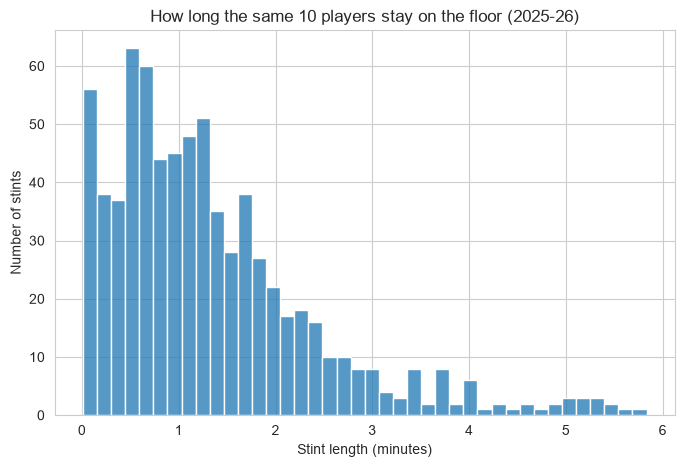

In [ ]:
plt.figure(figsize = (8, 5))

sns.histplot(clean['SECONDS'] / 60, bins = 40)

plt.xlabel('Stint length (minutes)')
plt.ylabel('Number of stints')
plt.title(f'How long the same 10 players stay on the floor ({SEASON})')
plt.show()